# Overlap between search engines

Upsetplot and quantification-error analysis for the six search engines
(best/MBR settings per tool) across all nine labs.

**Source data:** `Data/ProteoBench/intermediates.pkl`  
**Figure output:** `Figures/Figure_2/`

In [1]:
import os
import pickle

import pandas as pd
import matplotlib.pyplot as plt

from SCI_py.constants.plotting import LAB_COLORS, LAB_ORDER, SOFTWARE_COLORS
from SCI_py.plot.overlap_search_engines import (
    intermediate_to_upsetplotdf,
    get_boxplot_data,
    plot_upsetplot_panel,
    plot_boxplot_panel,
    plot_upsetplot_panel_supplemental,
    plot_boxplot_panel_supplemental
)

ZENODO_FOLDER = '/public/conode53/sam/SCI_paper/Zenodo'
DATA_PATH   = os.path.join(ZENODO_FOLDER, 'Data', 'ProteoBench')
FIGURE_PATH = '/home/sam/SCI/SCI/Figures/Figure_2/overlap_error'

In [2]:
with open(os.path.join(DATA_PATH, 'datapoints.pkl'), 'rb') as f:
    datapoints = pickle.load(f)
with open(os.path.join(DATA_PATH, 'intermediates.pkl'), 'rb') as f:
    intermediates = pickle.load(f)

print(f'{len(datapoints)} datapoints | {len(intermediates):,} intermediate rows')
print(f'Labs ({len(intermediates["lab"].unique())}): {sorted(intermediates["lab"].unique())}')
print(f'Search engines: {sorted(intermediates["search_engine"].unique())}')

75 datapoints | 1,020,110 intermediate rows
Labs (9): ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6', 'timsTOF_1', 'timsTOF_2', 'timsTOF_3']
Search engines: ['AlphaDIA', 'DIA-NN', 'FragPipe (DIA-NN quant)', 'MSAID', 'PEAKS', 'Spectronaut']


## Configuration

Adjust `BEST_SETTINGS` to compare different setting combinations.
`ORDERING_TOOLS` controls the order of tools in plots.

In [3]:
BEST_SETTINGS = {
    'AlphaDIA':                'Default',
    'MSAID':                   '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN':                  'DIANN 2.6',
    'FragPipe (DIA-NN quant)': 'standard',
    'PEAKS':                   'MBR TIC-norm',
    'Spectronaut':             'DirectDIA+ method-evaluation',
}

ORDERING_TOOLS = [
    'Spectronaut', 'DIA-NN', 'PEAKS',
    'FragPipe', 'AlphaDIA', 'MSAID',
]

MIN_PREC = 3   # minimum observed samples for a precursor to be included


def filter_best(df, best=BEST_SETTINGS):
    return df[
        df.apply(lambda r: best.get(r['search_engine']) == r['comments'], axis=1)
    ].copy()


inter_best = filter_best(intermediates)
inter_best['search_engine'] = inter_best['search_engine'].replace(
    {'FragPipe (DIA-NN quant)': 'FragPipe'}
)
inter_best['AbsQuantError'] = inter_best['epsilon'].abs()

LABS = [l for l in LAB_ORDER if l in inter_best['lab'].unique()]
print(f'{len(inter_best):,} rows after filtering | {len(LABS)} labs: {LABS}')
if len(inter_best) == 0:
    print('WARNING: no rows matched. Check BEST_SETTINGS values against the comments column.')

664,487 rows after filtering | 9 labs: ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6', 'timsTOF_1', 'timsTOF_2', 'timsTOF_3']


## Helper functions

- `intermediate_to_upsetplotdf`: filters to precursors seen in >= `min_prec` samples,
  returns an UpSet-compatible boolean DataFrame and a filtered long-format DataFrame.
- `get_boxplot_data`: computes per-tool |log2 FC error| for two subsets:
  precursors unique to that tool, and precursors detected by all tools.

## Per-lab computation

For each lab: filter intermediates, build the UpSet data structure, compute boxplot data.
Results are stored in `slices[lab]` with keys `ups` and `boxplot`.

In [4]:
slices = {}
for lab in LABS:
    df = inter_best[inter_best['lab'] == lab].copy()
    ups, inter_filt = intermediate_to_upsetplotdf(df, min_prec=MIN_PREC, per_condition=True)

    # Reorder index to match ORDERING_TOOLS
    new_idx = [t for t in ORDERING_TOOLS if t in ups.index.names]
    ups     = ups.reset_index().set_index(new_idx)

    bpd = get_boxplot_data(ups, inter_filt, column='AbsQuantError')
    slices[lab] = {'ups': ups, 'boxplot': bpd}

    n_prec  = inter_filt['precursor ion'].nunique()
    n_tools = len(ups.index.names)
    print(f'{lab:15s}: {n_prec:6,d} unique precursors across {n_tools} tools')

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


Astral_1       : 21,419 unique precursors across 6 tools


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


Astral_2       : 28,640 unique precursors across 6 tools
Astral_3       : 19,526 unique precursors across 6 tools


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


Astral_4       : 19,032 unique precursors across 6 tools
Astral_5       : 20,053 unique precursors across 6 tools


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


Astral_6       : 13,913 unique precursors across 2 tools
timsTOF_1      : 17,761 unique precursors across 6 tools


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


timsTOF_2      : 16,227 unique precursors across 6 tools
timsTOF_3      : 16,795 unique precursors across 6 tools


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


In [18]:
slices['timsTOF_2']['boxplot'].groupby('tool')['Quantified per software'].value_counts()

tool         Quantified per software
AlphaDIA     all tools                  2375
             unique to tool              516
DIA-NN       all tools                  2375
             unique to tool              844
FragPipe     all tools                  2375
             unique to tool              129
MSAID        all tools                  2375
             unique to tool              649
PEAKS        all tools                  2375
             unique to tool              159
Spectronaut  unique to tool             2473
             all tools                  2375
Name: count, dtype: int64

In [5]:
slices['Astral_2']['boxplot'].groupby('tool')['Quantified per software'].value_counts()

tool         Quantified per software
AlphaDIA     all tools                  7530
             unique to tool              616
DIA-NN       all tools                  7530
             unique to tool              933
FragPipe     all tools                  7530
             unique to tool              337
MSAID        all tools                  7530
             unique to tool              224
PEAKS        all tools                  7530
             unique to tool              802
Spectronaut  all tools                  7530
             unique to tool             4292
Name: count, dtype: int64

## Panel figures (paper)

Each figure is a 3×3 grid — one panel per lab — suitable for publication.
Figures are saved to `Figures/Figure_2/{png,svg,pdf}/`.

In [6]:
LABS

['Astral_1',
 'Astral_2',
 'Astral_3',
 'Astral_4',
 'Astral_5',
 'Astral_6',
 'timsTOF_1',
 'timsTOF_2',
 'timsTOF_3']

In [7]:
SELECTION_SUPPLEMENTAL = [
    'Astral_1',
    # 'Astral_2',
    'Astral_3',
    'Astral_4',
    'Astral_5',
    'Astral_6',
    'timsTOF_1',
    # 'timsTOF_2',
    'timsTOF_3'
]

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

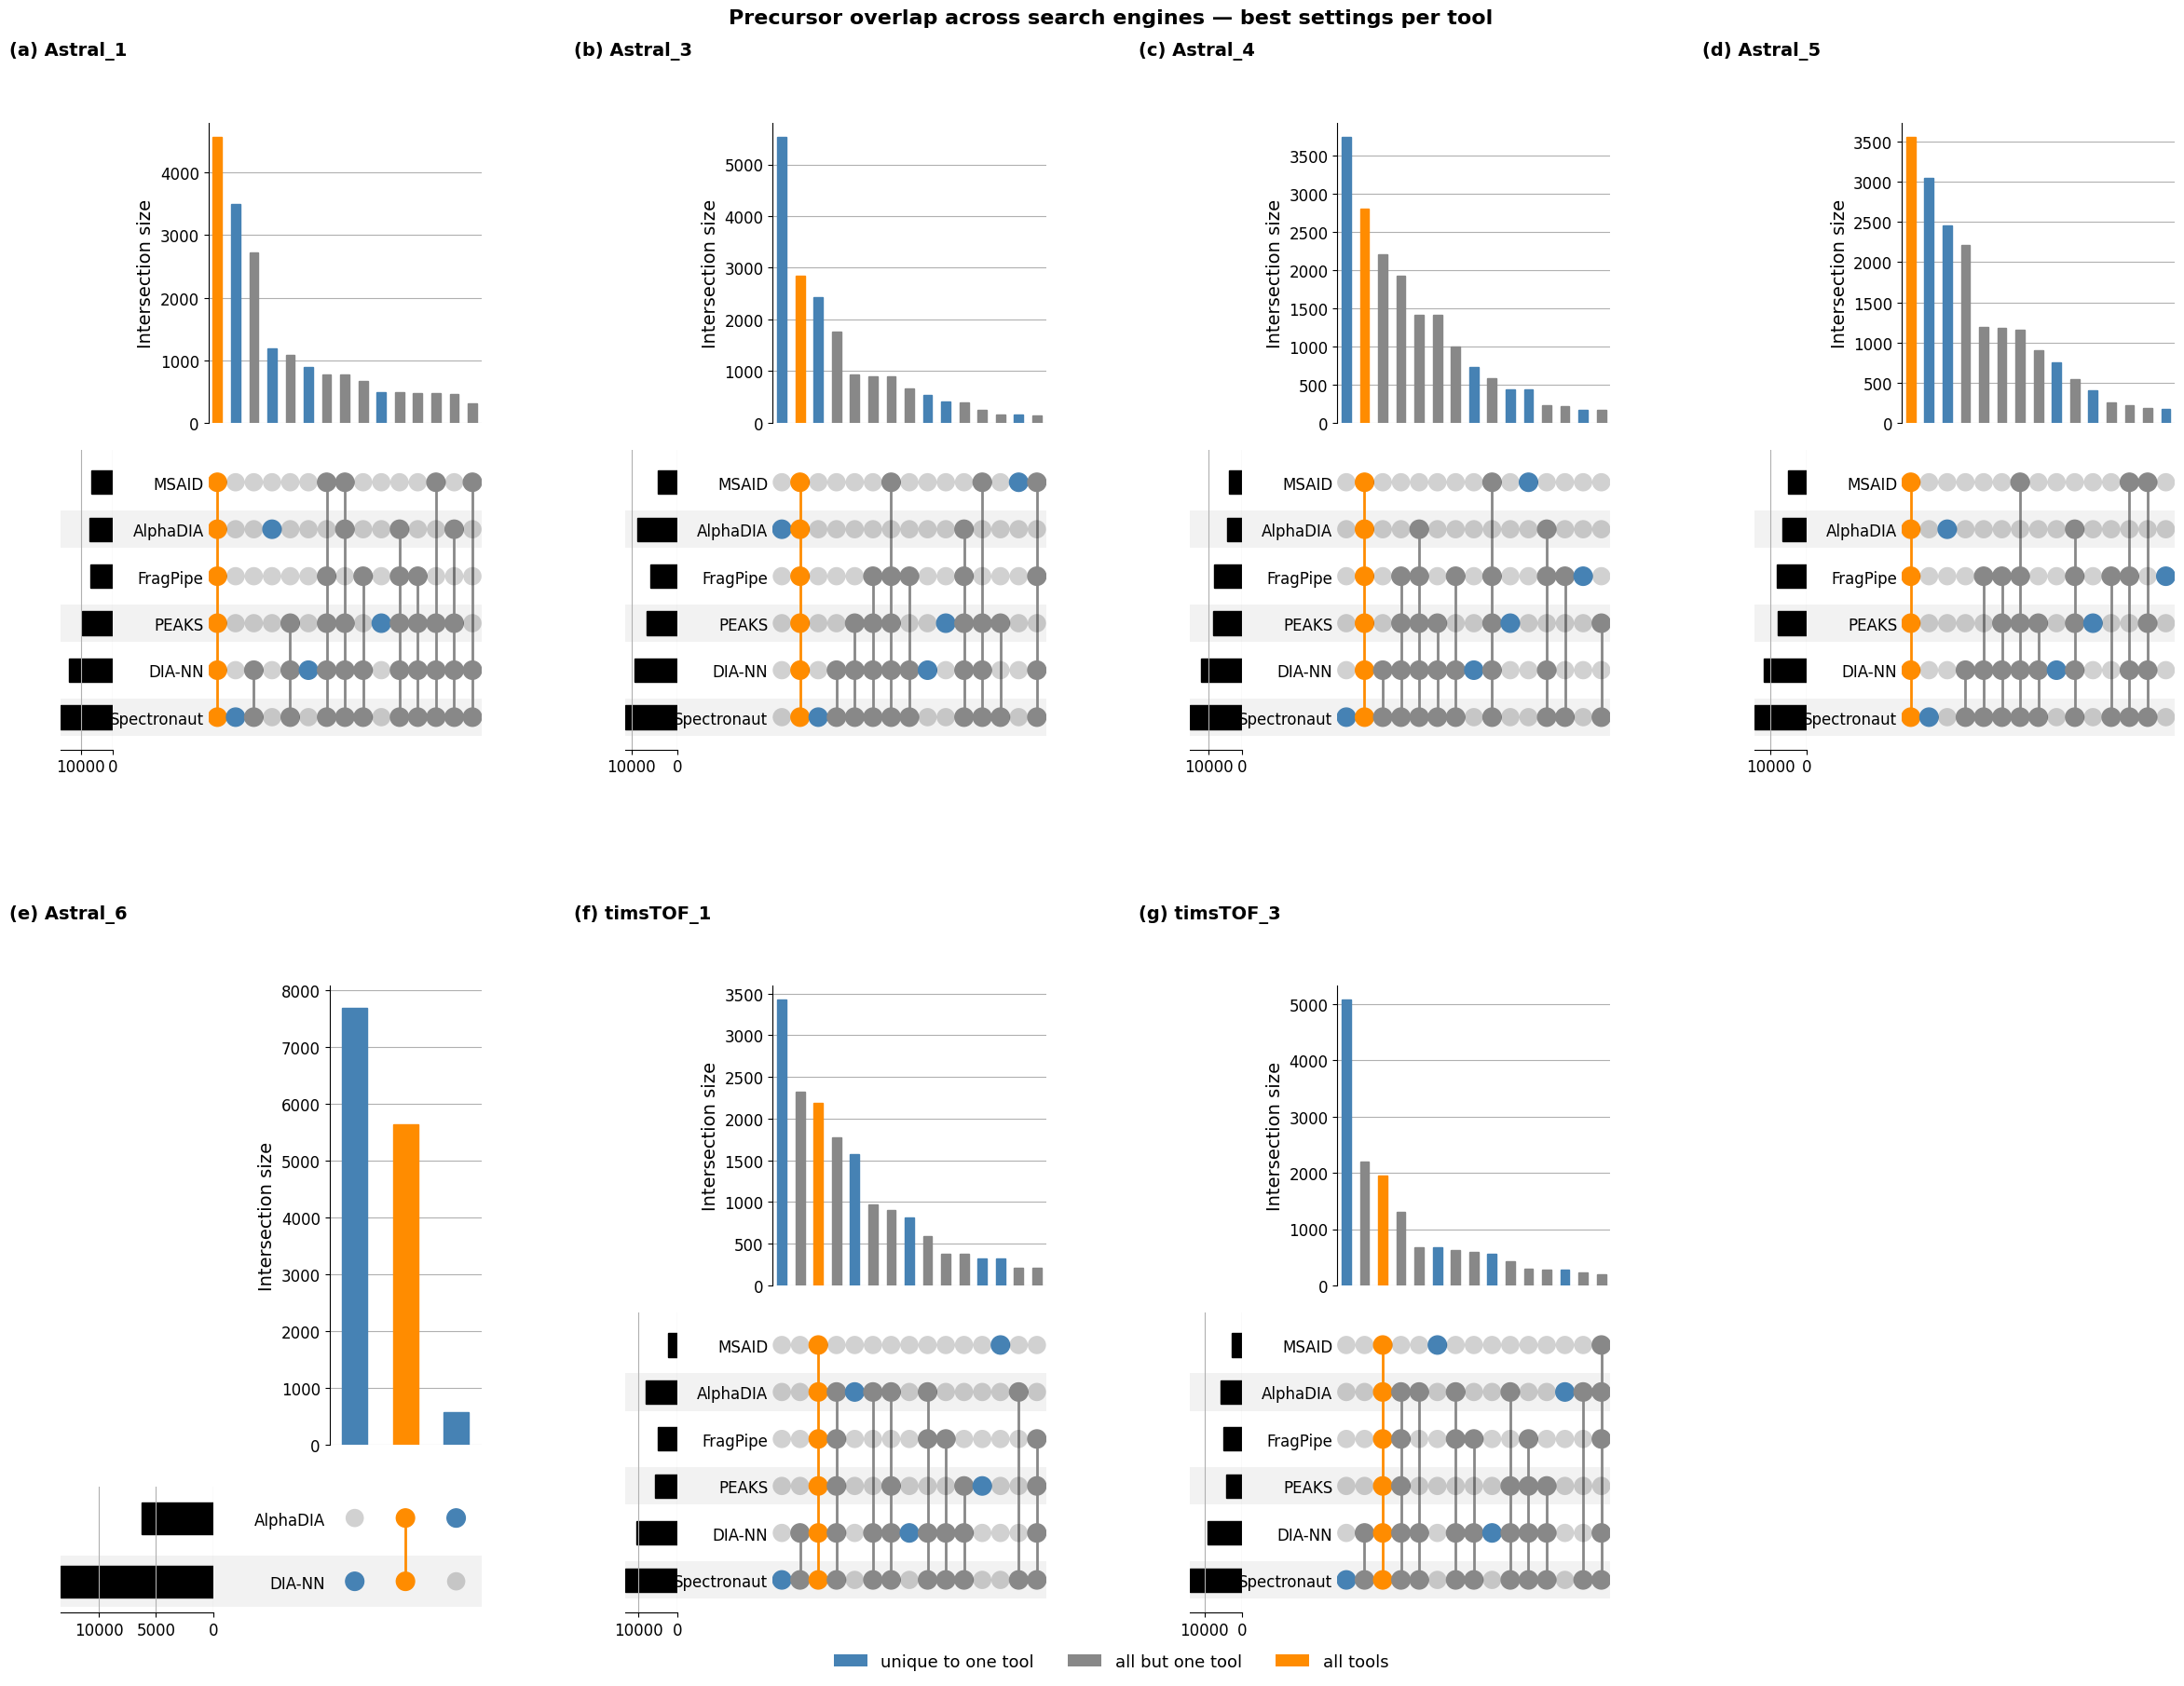

In [8]:
plot_upsetplot_panel_supplemental(
    slices         = slices,
    labs           = SELECTION_SUPPLEMENTAL,
    nrow = 2,
    ncol = 4,
    ordering_tools = ORDERING_TOOLS,
    sort_by_size=True,
    max_upsets=15
)

/home/sam/SCI/SCI/SCI_py/SCI_py/plot/overlap_search_engines.py:179: PerformanceWarning: indexing past lexsort depth may impact performance.
  desired     = [tup for tup in desired if tup in ups_filt.index]
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of 

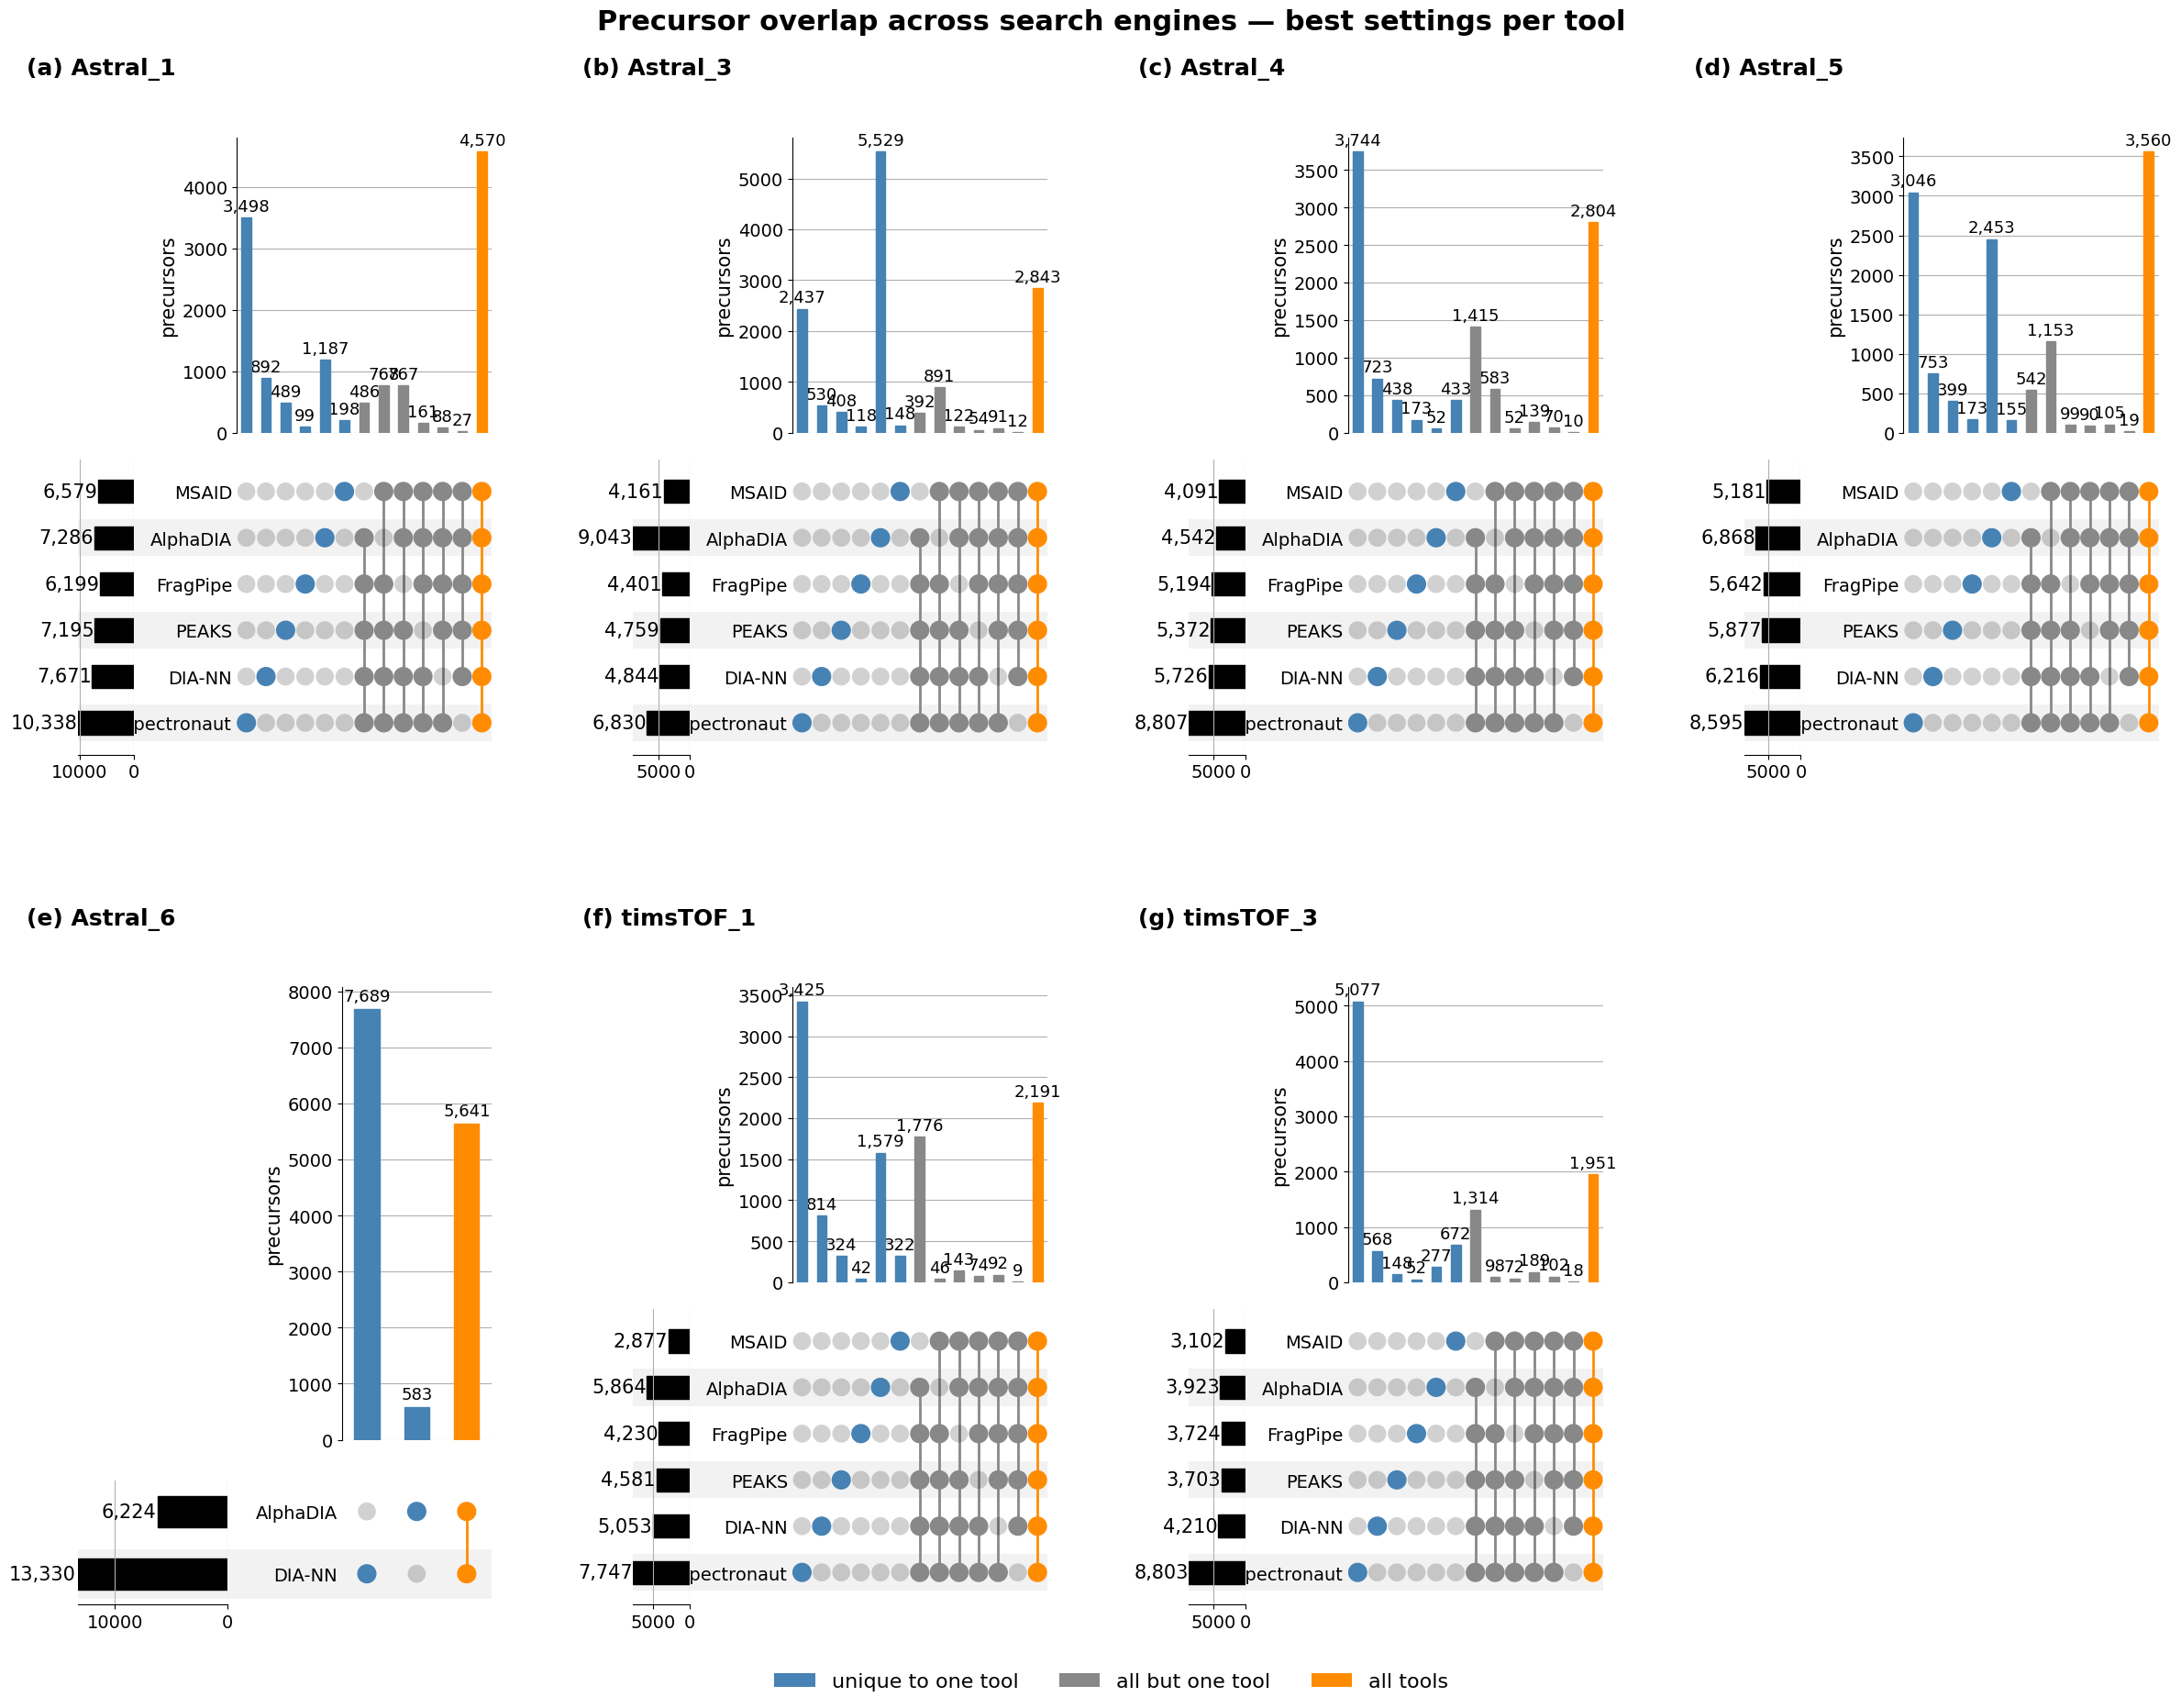

In [9]:
plot_upsetplot_panel(
    slices         = slices,
    labs           = SELECTION_SUPPLEMENTAL,
    nrow = 2,
    ncol = 4,
    ordering_tools = ORDERING_TOOLS,
    save_dir       = FIGURE_PATH,
    show           = True,
)

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

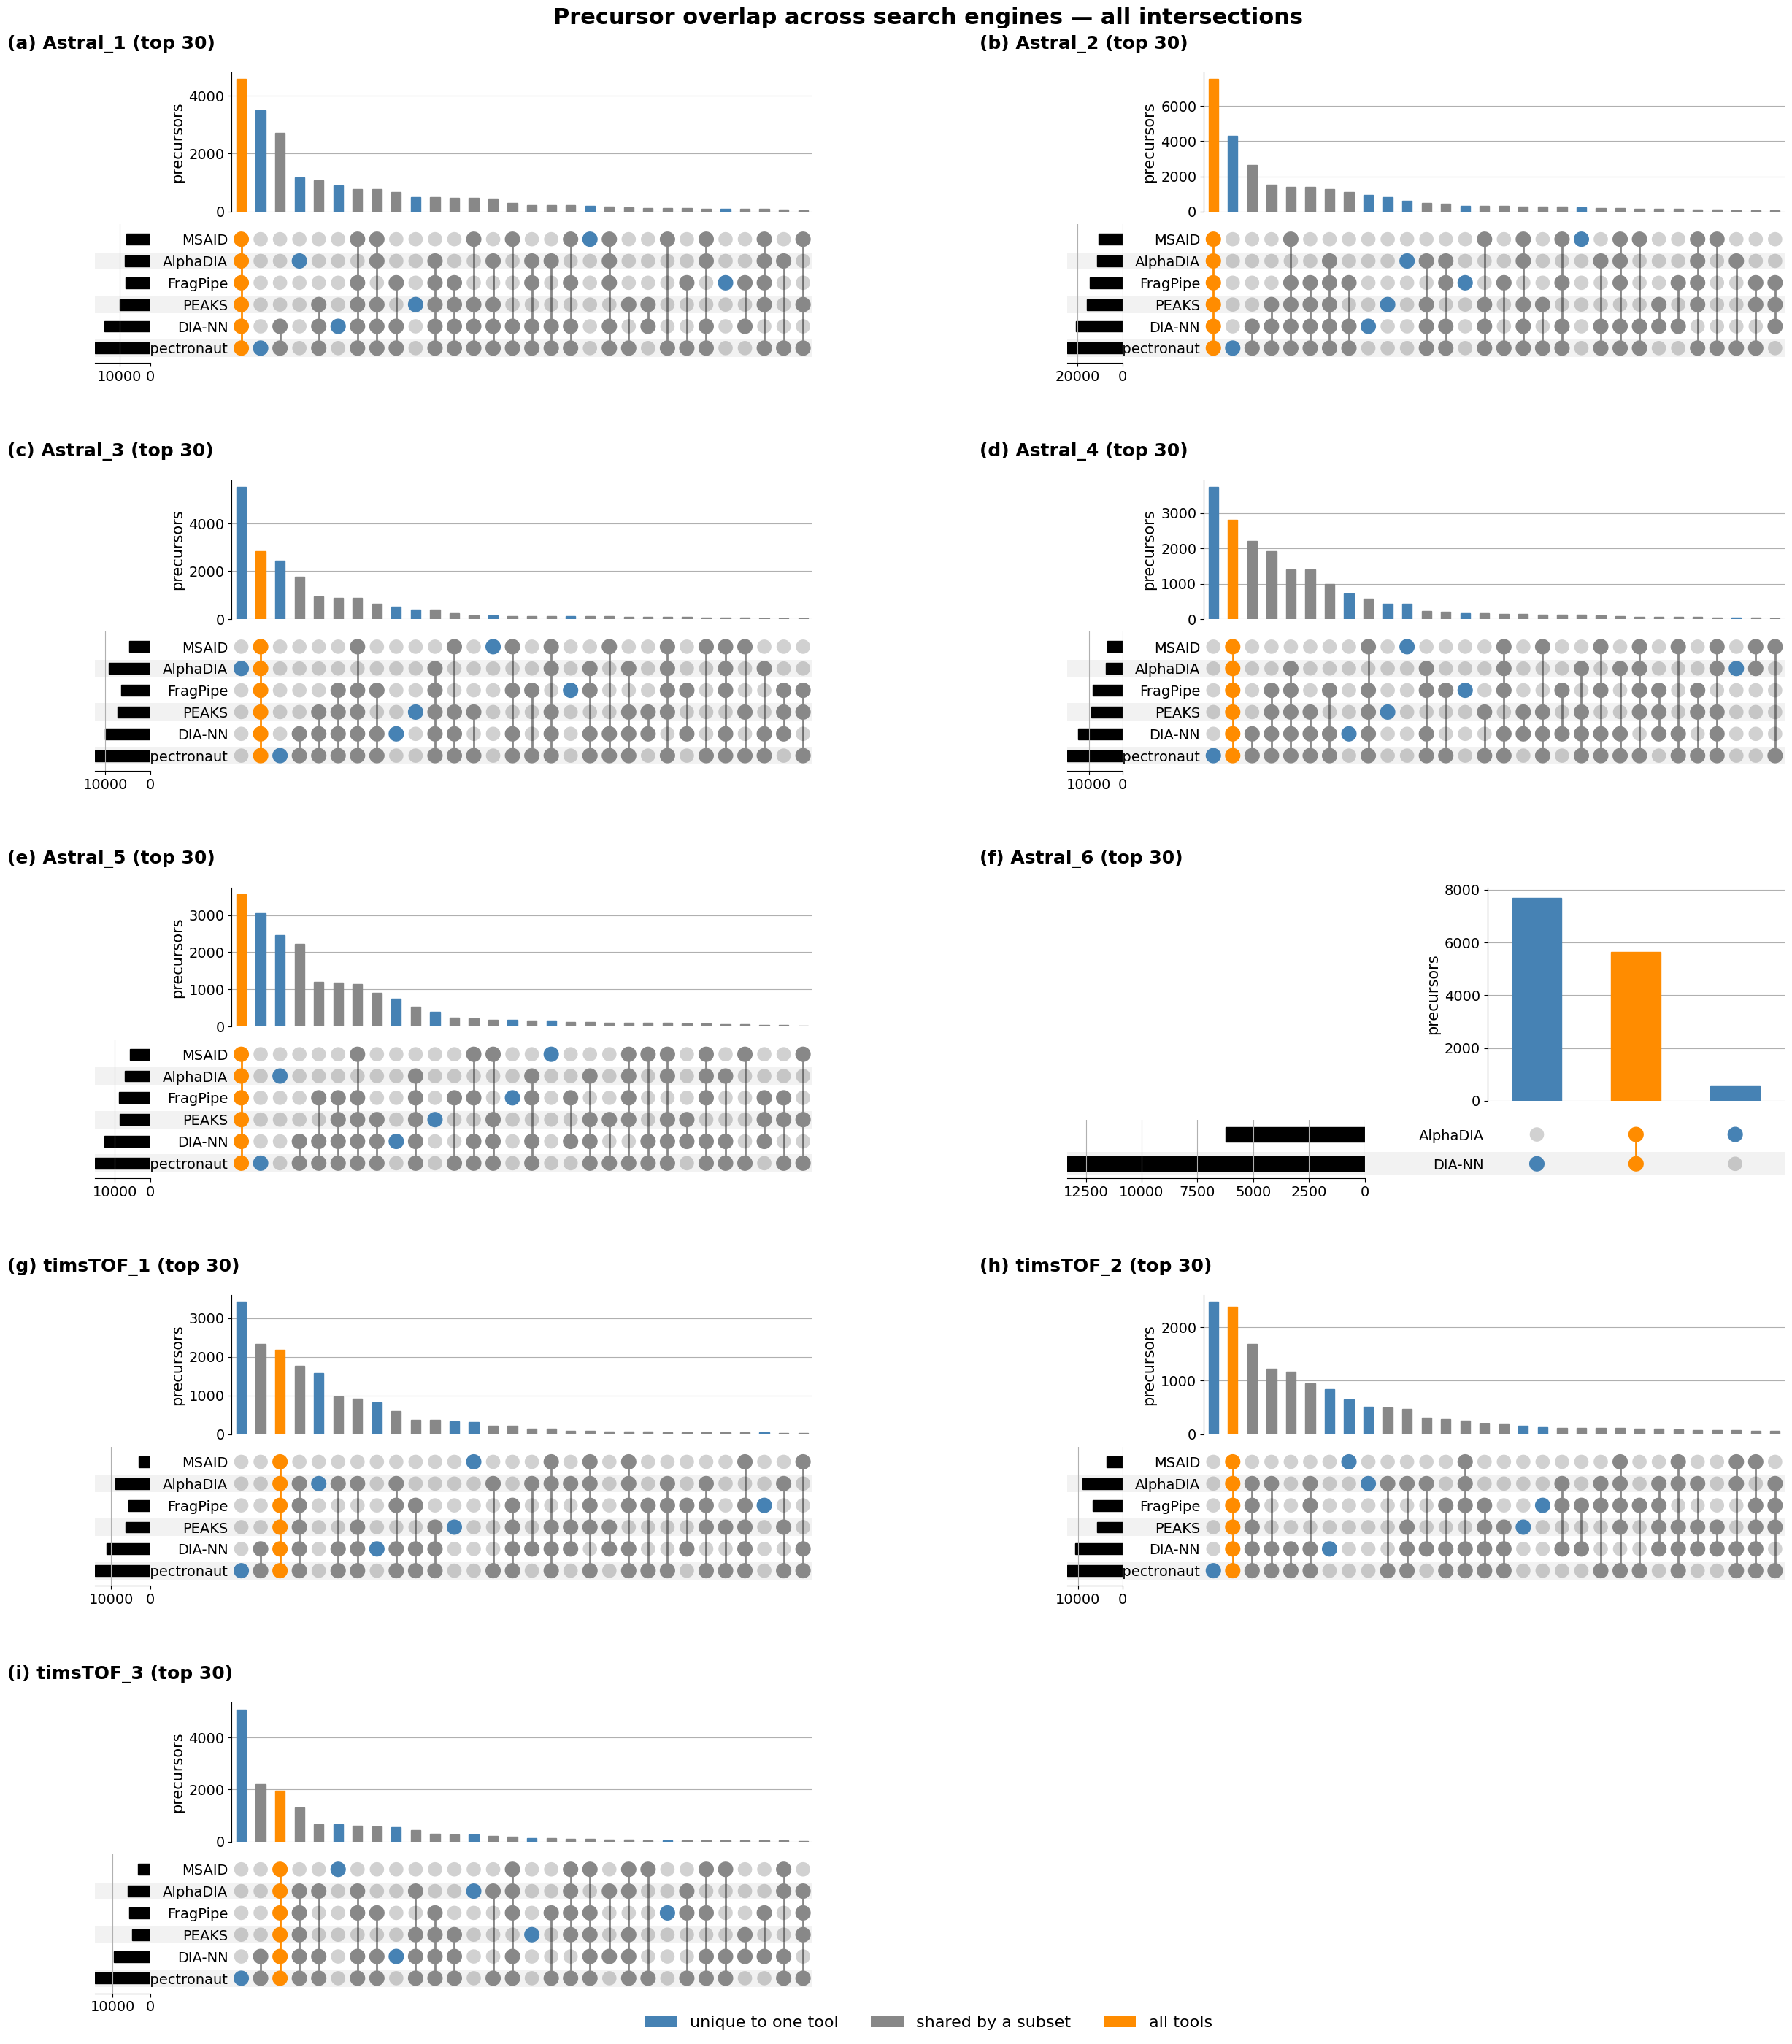

In [10]:
from SCI_py.plot.overlap_search_engines import plot_full_upsetplot_panel

plot_full_upsetplot_panel(
    slices         = slices,
    labs           = LABS,            # all 9 labs
    ordering_tools = ORDERING_TOOLS,
    ncol           = 2,
    max_upsets     = 30,            # or e.g. 20 to cap the smallest intersections
    save_dir       = FIGURE_PATH,
    filename       = 'upsetplot_panel_full',
    show           = True,
)

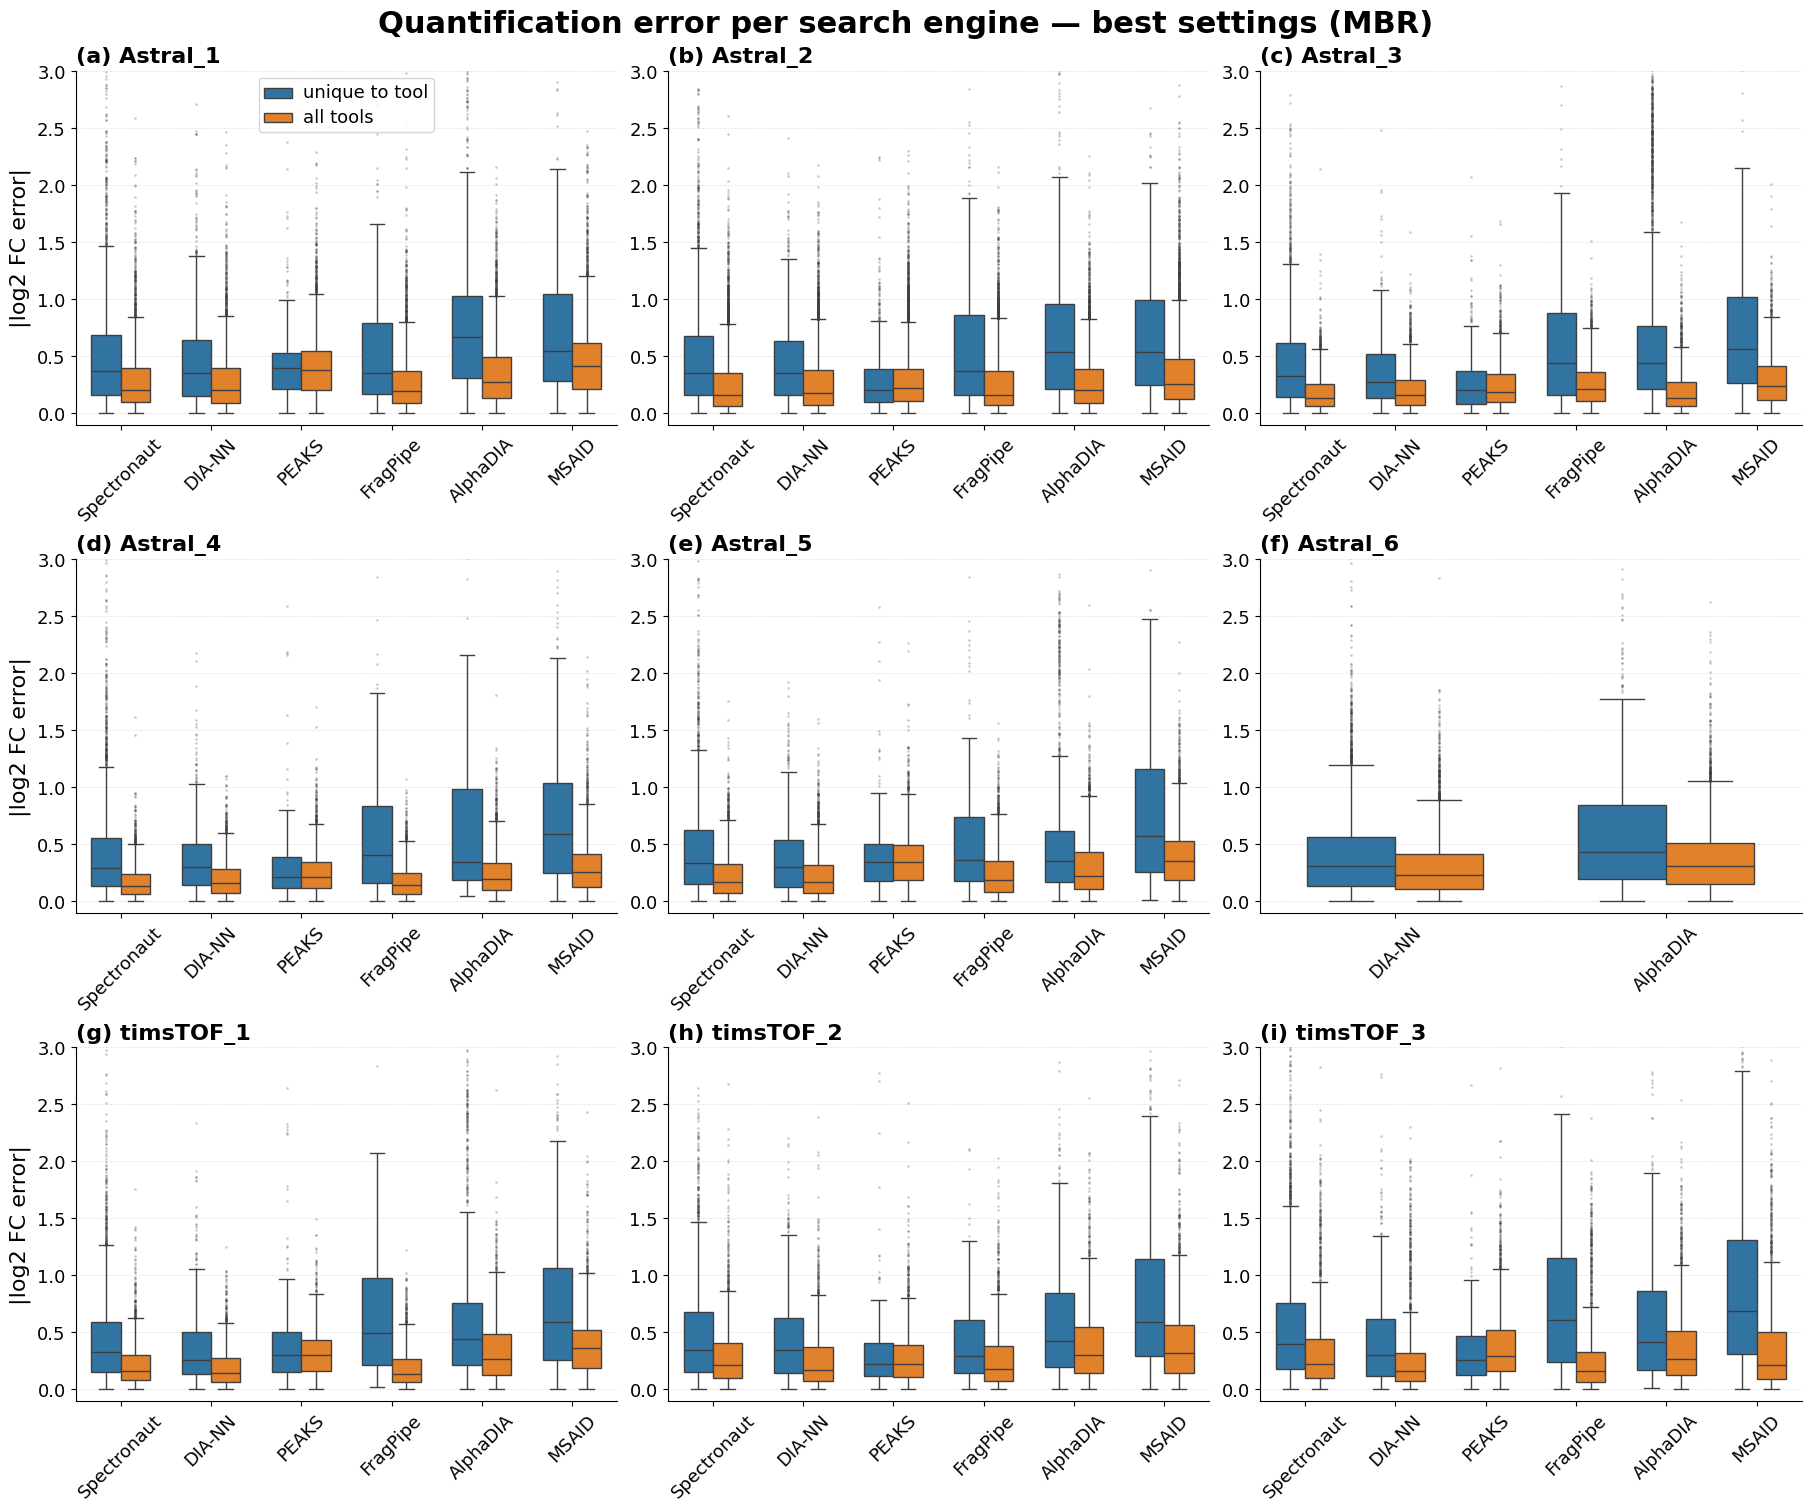

In [11]:
plot_boxplot_panel(
    slices         = slices,
    labs           = LABS,
    ordering_tools = ORDERING_TOOLS,
    save_dir       = FIGURE_PATH,
    show           = True,
)

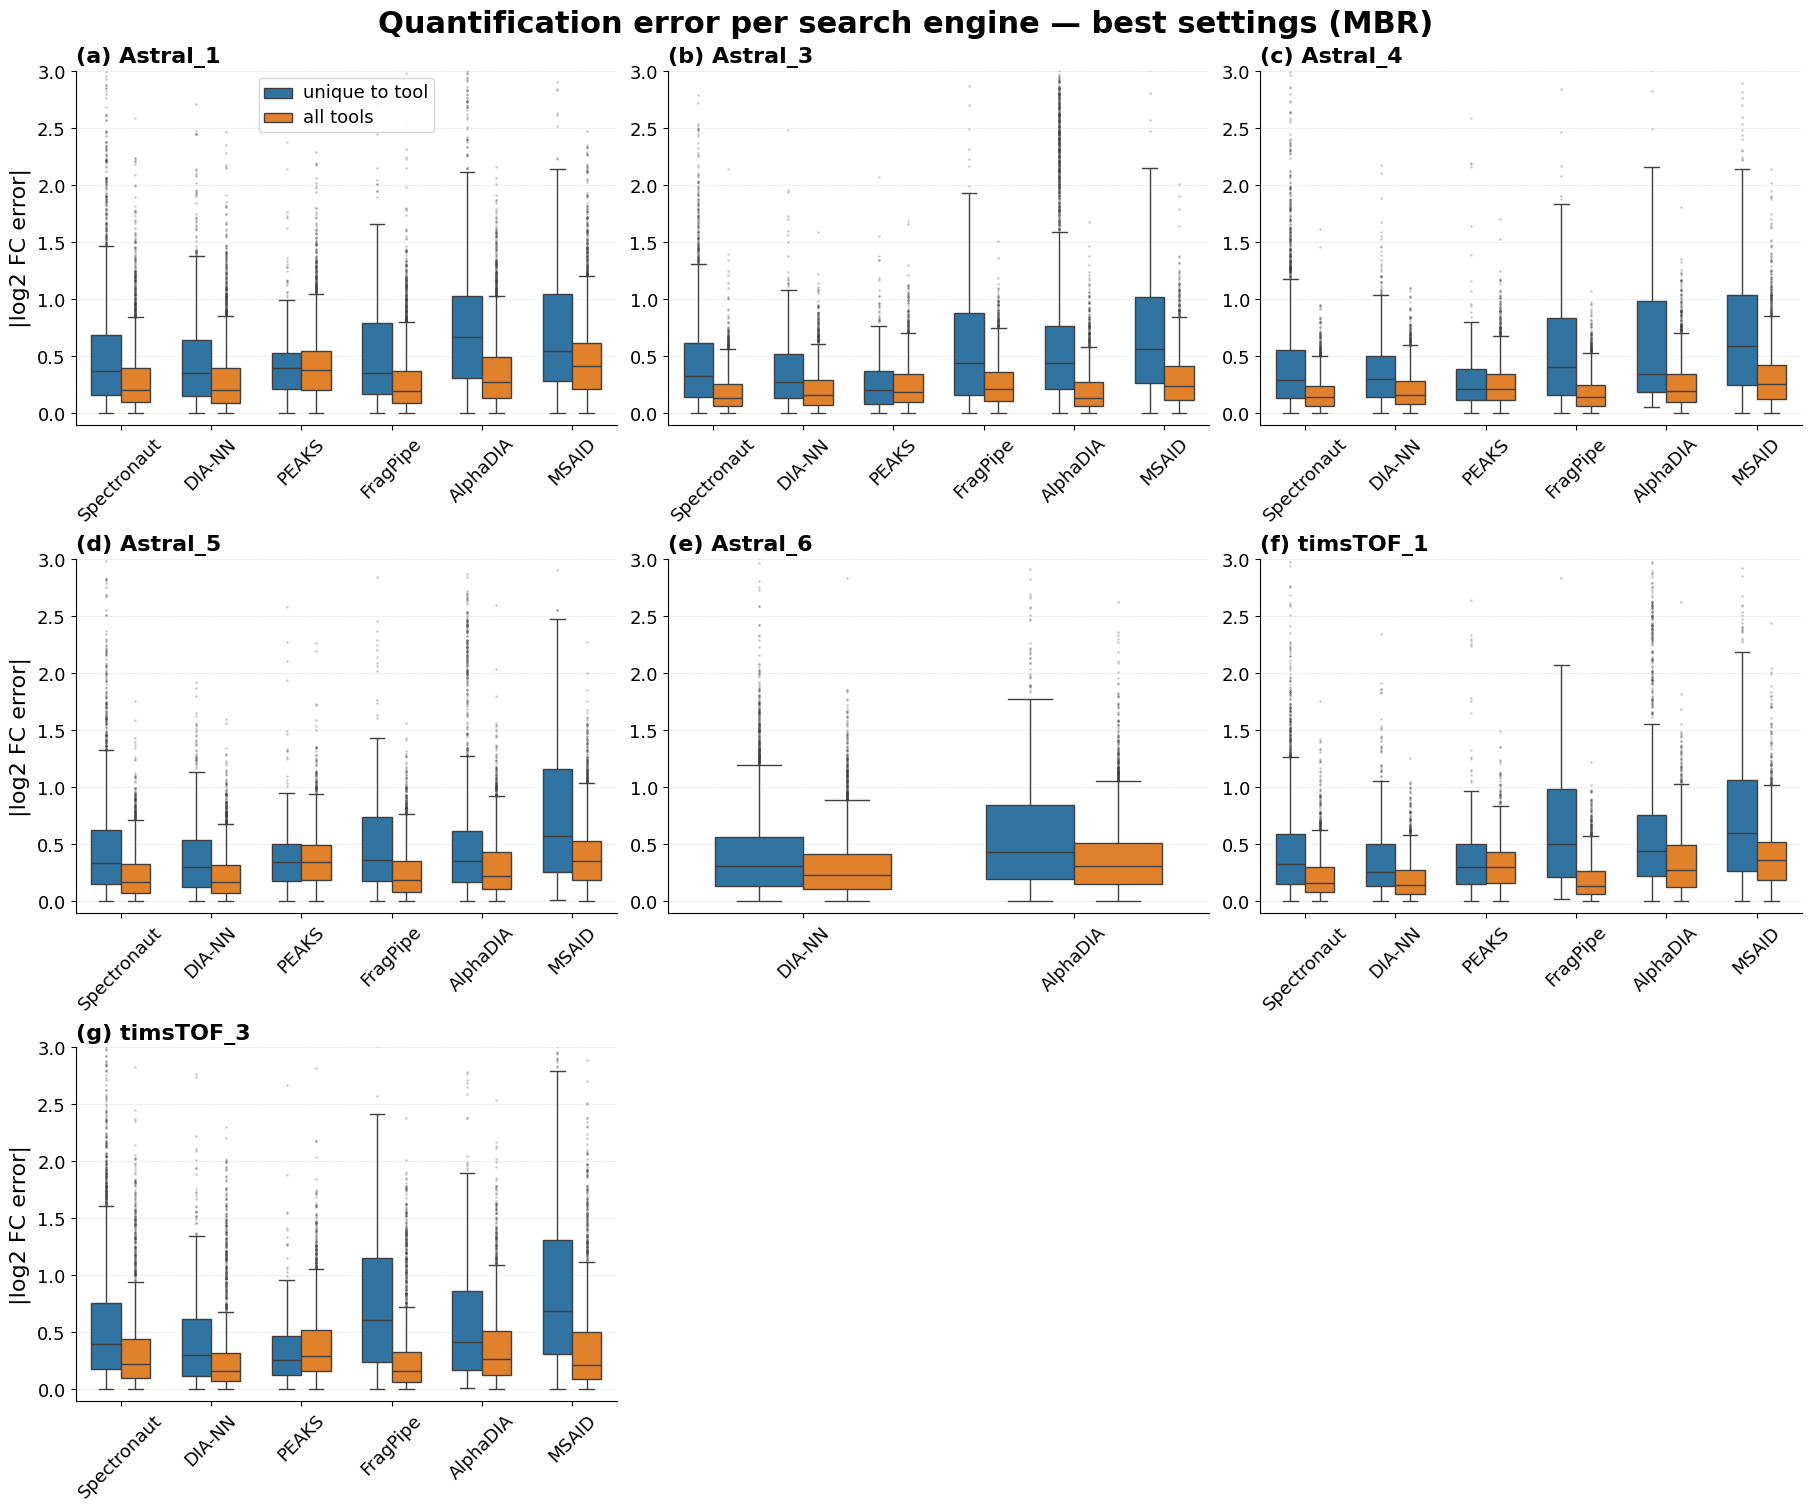

In [12]:
plot_boxplot_panel(
    slices         = slices,
    labs           = SELECTION_SUPPLEMENTAL,
    ordering_tools = ORDERING_TOOLS,
    save_dir       = FIGURE_PATH,
    filename = 'boxplot_supplemental',
    show           = True,
)

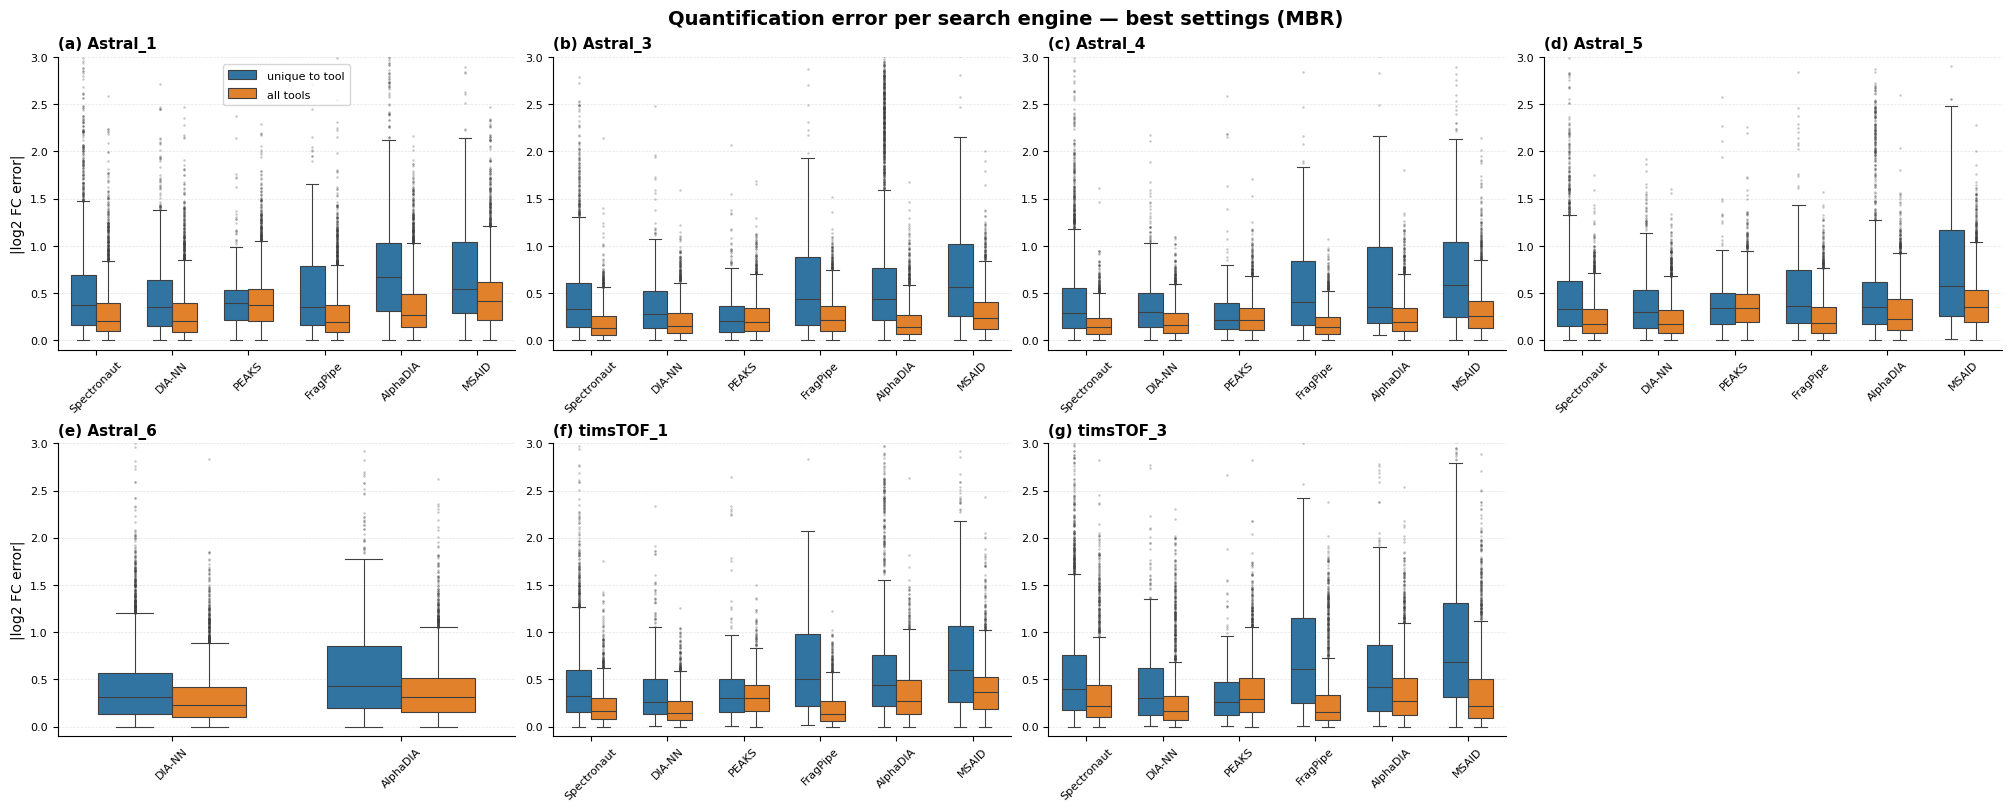

In [13]:
plot_boxplot_panel_supplemental(
    slices         = slices,
    labs           = SELECTION_SUPPLEMENTAL,
    ordering_tools = ORDERING_TOOLS,
    save_dir       = FIGURE_PATH,
    show           = True,
)